# 📊 Geldium Customer Delinquency Risk — Exploratory Data Analysis (EDA)

## 📌 Project Overview

This notebook presents an Exploratory Data Analysis (EDA) of Geldium's customer dataset as part of the Tata iQ GenAI Powered Data Analytics Job Simulation.

The main objective of this analysis is to understand the dataset, assess its quality and completeness, identify missing or inconsistent data, and explore patterns that may be associated with customer delinquency.

### 🎯 Objectives

- Understand the structure and key attributes of the dataset.
- Identify missing, duplicate, inconsistent, or unusual data.
- Explore relationships between customer financial attributes and delinquency.
- Identify potential early risk indicators for delinquency prediction.
- Document key findings and data-quality issues for future predictive modeling.

### 🔍 Analysis Flow

**Dataset Understanding → Data Quality Check → Missing Values → Outliers & Anomalies → Exploratory Analysis → Risk Indicators → Key Findings**

> **Note:** This notebook focuses on Exploratory Data Analysis. Predictive modeling is not performed at this stage.

## 1. Importing Required Libraries

We will use Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn to load, inspect, clean, and visualize the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Dataset

The dataset contains customer-level financial and payment information that will be analyzed to understand data quality and potential delinquency risk indicators.

In [2]:
df = pd.read_excel("Delinquency_prediction_dataset.xlsx")

df.head()

,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,165580.0,398.0,0.390502,3,0,16310.0,0.317396,EMP,18,Student,Los Angeles,Late,Late,Missed,Late,Missed,Late
1,CUST0002,69,100999.0,493.0,0.312444,6,1,17401.0,0.196093,Self-employed,0,Standard,Phoenix,Missed,Missed,Late,Missed,On-time,On-time
2,CUST0003,46,188416.0,500.0,0.359930,0,0,13761.0,0.301655,Self-employed,1,Platinum,Chicago,Missed,Late,Late,On-time,Missed,Late
3,CUST0004,32,101672.0,413.0,0.371400,3,0,88778.0,0.264794,Unemployed,15,Platinum,Phoenix,Late,Missed,Late,Missed,Late,Late
4,CUST0005,60,38524.0,487.0,0.234716,2,0,13316.0,0.510583,Self-employed,11,Standard,Phoenix,Missed,On-time,Missed,Late,Late,Late


## 3. Understanding the Dataset Structure

First, we will examine the number of records, available variables, data types, and basic statistics to understand the structure of the dataset.

In [3]:
df.shape

(500, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           500 non-null    object 
 1   Age                   500 non-null    int64  
 2   Income                461 non-null    float64
 3   Credit_Score          498 non-null    float64
 4   Credit_Utilization    500 non-null    float64
 5   Missed_Payments       500 non-null    int64  
 6   Delinquent_Account    500 non-null    int64  
 7   Loan_Balance          471 non-null    float64
 8   Debt_to_Income_Ratio  500 non-null    float64
 9   Employment_Status     500 non-null    object 
 10  Account_Tenure        500 non-null    int64  
 11  Credit_Card_Type      500 non-null    object 
 12  Location              500 non-null    object 
 13  Month_1               500 non-null    object 
 14  Month_2               500 non-null    object 
 15  Month_3               5

### Initial Data Quality Observation

The dataset contains 500 customer records and 19 variables. The dataset includes both numerical and categorical variables. Missing values were identified in Income (39 records), Credit_Score (2 records), and Loan_Balance (29 records). These missing values should be investigated and an appropriate treatment strategy should be determined before predictive modeling.

In [5]:
df.isnull().sum()

Customer_ID              0
Age                      0
Income                  39
Credit_Score             2
Credit_Utilization       0
Missed_Payments          0
Delinquent_Account       0
Loan_Balance            29
Debt_to_Income_Ratio     0
Employment_Status        0
Account_Tenure           0
Credit_Card_Type         0
Location                 0
Month_1                  0
Month_2                  0
Month_3                  0
Month_4                  0
Month_5                  0
Month_6                  0
dtype: int64

### Missing Data Observation

The dataset contains missing values in three variables: Income (39 records), Loan_Balance (29 records), and Credit_Score (2 records). The remaining variables contain no missing values. These missing values need to be assessed before predictive modeling because incomplete financial information may affect delinquency analysis.

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["Employment_Status"].value_counts()

Employment_Status
Unemployed       93
retired          87
Employed         82
EMP              81
Self-employed    80
employed         77
Name: count, dtype: int64

### Categorical Data Consistency

The `Employment_Status` variable contains inconsistent category labels. 
For example, `Employed`, `employed`, and `EMP` appear to represent the same employment category but are recorded differently. 
The `retired` category also uses inconsistent capitalization compared with the other labels. 
These inconsistencies should be standardized before further analysis to avoid treating the same category as separate groups.

In [8]:
df.describe()

,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Account_Tenure
count,500.000000,461.000000,498.000000,500.000000,500.000000,500.000000,471.000000,500.000000,500.000000
mean,46.266000,108379.893709,577.716867,0.491446,2.968000,0.160000,48654.428875,0.298862,9.740000
std,16.187629,53662.723741,168.881211,0.197103,1.946935,0.366973,29395.537273,0.094521,5.923054
min,18.000000,15404.000000,301.000000,0.050000,0.000000,0.000000,612.000000,0.100000,0.000000
25%,33.000000,62295.000000,418.250000,0.356486,1.000000,0.000000,23716.500000,0.233639,5.000000
50%,46.500000,107658.000000,586.000000,0.485636,3.000000,0.000000,45776.000000,0.301634,10.000000
75%,59.250000,155734.000000,727.250000,0.634440,5.000000,0.000000,75546.500000,0.362737,15.000000
max,74.000000,199943.000000,847.000000,1.025843,6.000000,1.000000,99620.000000,0.552956,19.000000


### Numerical Data Quality Observations

The numerical summary shows that most variables have plausible ranges with no immediately obvious invalid values.

- Age ranges from 18 to 74 years.
- Credit Score ranges from 301 to 847.
- Missed Payments ranges from 0 to 6.
- Delinquent_Account is a binary variable with values 0 and 1.
- Account Tenure ranges from 0 to 19 years.
- Credit_Utilization has a maximum value of approximately 1.026 (102.6%), which is an unusual value and should be investigated further rather than automatically treated as an error.
- Missing values are present in Income, Credit_Score, and Loan_Balance.

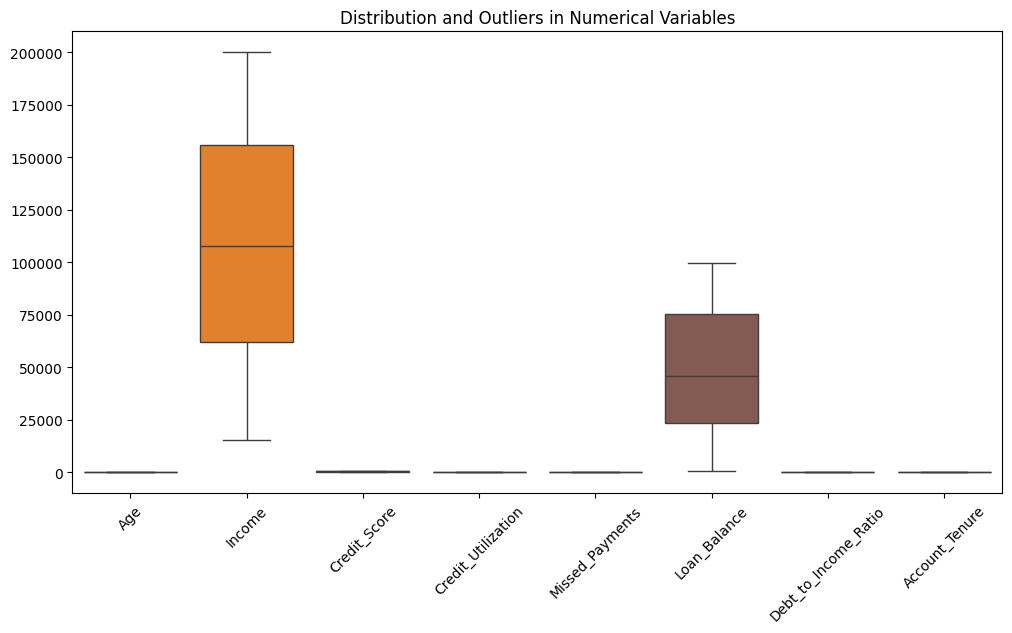

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[
    ["Age", "Income", "Credit_Score",
     "Credit_Utilization", "Missed_Payments",
     "Loan_Balance", "Debt_to_Income_Ratio",
     "Account_Tenure"]
])
plt.xticks(rotation=45)
plt.title("Distribution and Outliers in Numerical Variables")
plt.show()

In [10]:
numeric_cols = [
    "Age", "Income", "Credit_Score",
    "Credit_Utilization", "Missed_Payments",
    "Loan_Balance", "Debt_to_Income_Ratio",
    "Account_Tenure"
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "→", len(outliers), "possible outliers")

Age → 0 possible outliers
Income → 0 possible outliers
Credit_Score → 0 possible outliers
Credit_Utilization → 0 possible outliers
Missed_Payments → 0 possible outliers
Loan_Balance → 0 possible outliers
Debt_to_Income_Ratio → 0 possible outliers
Account_Tenure → 0 possible outliers


### Outlier Analysis

The IQR-based outlier analysis identified no potential outliers across the numerical variables. Therefore, no numerical records were removed based on the IQR method.

Credit_Utilization has a maximum value of approximately 1.026 (102.6%), which appears unusual, but it was not identified as a statistical outlier by the IQR method. Therefore, it is retained for further analysis rather than being removed automatically.

In [11]:
df["Delinquent_Account"].value_counts()


Delinquent_Account
0    420
1     80
Name: count, dtype: int64

In [12]:
df["Delinquent_Account"].value_counts(normalize=True) * 100

Delinquent_Account
0    84.0
1    16.0
Name: proportion, dtype: float64

### Delinquency Distribution

The dataset contains 500 customer records. 420 customers (84%) are classified as non-delinquent, while 80 customers (16%) are classified as delinquent. Therefore, the delinquent class represents a minority of the observations and the target variable shows an imbalanced class distribution.

In [13]:
df.groupby("Delinquent_Account")["Missed_Payments"].mean()

Delinquent_Account
0    2.990476
1    2.850000
Name: Missed_Payments, dtype: float64

### Missed Payments vs Delinquency

The average number of missed payments is 2.99 for non-delinquent customers and 2.85 for delinquent customers. Contrary to an initial expectation, delinquent customers do not show a higher average number of missed payments in this dataset. Therefore, `Missed_Payments` alone does not appear to be a strong positive indicator of delinquency based on this group-level comparison.

In [14]:
df.groupby("Delinquent_Account")["Credit_Score"].mean()

Delinquent_Account
0    575.145933
1    591.150000
Name: Credit_Score, dtype: float64

### Credit Score vs Delinquency

The average credit score is 575.15 for non-delinquent customers and 591.15 for delinquent customers. Interestingly, delinquent customers have a slightly higher average credit score in this dataset. Therefore, credit score alone does not show the expected negative relationship with delinquency based on this group-level comparison. This observation should not be interpreted as a causal relationship.

In [15]:
df.groupby("Delinquent_Account")["Loan_Balance"].mean()

Delinquent_Account
0    48708.756281
1    48358.232877
Name: Loan_Balance, dtype: float64

### Loan Balance vs Delinquency

The average loan balance is approximately ₹48,708.76 for non-delinquent customers and ₹48,358.23 for delinquent customers. The difference between the two groups is relatively small, indicating that loan balance alone does not show a strong difference between delinquent and non-delinquent customers in this dataset. This is a group-level observation and does not establish a causal relationship.

In [16]:
df.groupby("Delinquent_Account")["Debt_to_Income_Ratio"].mean()

Delinquent_Account
0    0.297445
1    0.306301
Name: Debt_to_Income_Ratio, dtype: float64

### Debt-to-Income Ratio vs Delinquency

The average Debt-to-Income Ratio is 0.2974 (29.74%) for non-delinquent customers and 0.3063 (30.63%) for delinquent customers. Delinquent customers therefore show a slightly higher average DTI in this dataset. This suggests that higher debt relative to income may be a potential delinquency risk indicator, although the observed difference is relatively small and further analysis is required.

In [17]:
df.groupby("Delinquent_Account")["Credit_Utilization"].mean()

Delinquent_Account
0    0.488505
1    0.506887
Name: Credit_Utilization, dtype: float64

### Credit Utilization vs Delinquency

The average credit utilization is 48.85% for non-delinquent customers and 50.69% for delinquent customers. Delinquent customers therefore show slightly higher average credit utilization in this dataset. This suggests that higher credit utilization may be a potential delinquency risk indicator, although the difference between the groups is relatively small and does not establish causation.

In [18]:
df.groupby("Delinquent_Account")["Account_Tenure"].mean()

Delinquent_Account
0    9.842857
1    9.200000
Name: Account_Tenure, dtype: float64

### Account Tenure vs Delinquency

The average account tenure is 9.84 years for non-delinquent customers and 9.20 years for delinquent customers. Delinquent customers therefore have a slightly lower average account tenure in this dataset. This suggests that shorter account tenure may be a potential delinquency risk indicator, although the difference is relatively small and further analysis is required.

### Key Numerical Patterns by Delinquency Status

| Variable | Non-delinquent | Delinquent | Initial observation |
|---|---:|---:|---|
| Missed Payments | 2.99 | 2.85 | Delinquent group lower |
| Credit Score | 575.15 | 591.15 | Delinquent group higher |
| Loan Balance | ₹48,708.76 | ₹48,358.23 | Almost same |
| DTI | 29.74% | 30.63% | Delinquent group slightly higher |
| Credit Utilization | 48.85% | 50.69% | Delinquent group slightly higher |
| Account Tenure | 9.84 yrs | 9.20 yrs | Delinquent group slightly lower |

In [19]:
pd.crosstab(df["Employment_Status"], df["Delinquent_Account"])

Delinquent_Account,0,1
Employment_Status,,
EMP,69,12
Employed,67,15
Self-employed,67,13
Unemployed,75,18
employed,65,12
retired,77,10


In [20]:
pd.crosstab(
    df["Employment_Status"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Employment_Status,,
EMP,85.185185,14.814815
Employed,81.707317,18.292683
Self-employed,83.750000,16.250000
Unemployed,80.645161,19.354839
employed,84.415584,15.584416
retired,88.505747,11.494253


In [21]:
df["Employment_Status_Clean"] = (
    df["Employment_Status"]
    .replace({
        "EMP": "Employed",
        "employed": "Employed",
        "retired": "Retired"
    })
)

In [22]:
df["Employment_Status_Clean"].value_counts()

Employment_Status_Clean
Employed         240
Unemployed        93
Retired           87
Self-employed     80
Name: count, dtype: int64

In [23]:
pd.crosstab(
    df["Employment_Status_Clean"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Employment_Status_Clean,,
Employed,83.750000,16.250000
Retired,88.505747,11.494253
Self-employed,83.750000,16.250000
Unemployed,80.645161,19.354839


### Employment Status vs Delinquency

After standardizing inconsistent employment labels, four employment categories were analyzed. The observed delinquency rate was 19.35% among unemployed customers, 16.25% among employed customers, 16.25% among self-employed customers, and 11.49% among retired customers. In this dataset, unemployed customers show the highest observed delinquency rate, while retired customers show the lowest. Employment status may therefore be a useful variable to consider when analyzing delinquency risk, although this association does not establish causation.

In [24]:
df.groupby("Delinquent_Account")["Age"].mean()

Delinquent_Account
0    46.107143
1    47.100000
Name: Age, dtype: float64

### Age vs Delinquency

The average age is 46.11 years for non-delinquent customers and 47.10 years for delinquent customers. The delinquent group therefore has a slightly higher average age, with a difference of approximately one year. However, the difference is relatively small, so age alone does not appear to show a strong relationship with delinquency based on this group-level comparison.

In [25]:
df[["Month_1", "Month_2", "Month_3", "Month_4", "Month_5", "Month_6"]].describe()

,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
count,500,500,500,500,500,500
unique,3,3,3,3,3,3
top,On-time,Late,Late,Late,Missed,Late
freq,177,173,169,181,187,172


In [26]:
pd.crosstab(
    df["Month_1"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Month_1,,
Late,88.679245,11.320755
Missed,83.536585,16.463415
On-time,80.225989,19.774011


### Month 1 Payment Status vs Delinquency

Month 1 payment behavior shows an unexpected pattern. The observed delinquency rate is 11.32% for customers classified as Late, 16.46% for customers classified as Missed, and 19.77% for customers classified as On-time. Contrary to the expected relationship, the On-time category has the highest observed delinquency rate in Month 1. This suggests that Month 1 payment status alone does not show the expected relationship with delinquency in this dataset.

In [27]:
pd.crosstab(
    df["Month_2"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Month_2,,
Late,84.971098,15.028902
Missed,84.431138,15.568862
On-time,82.500000,17.500000


### Month 2 Payment Status vs Delinquency

Month 2 shows a similar pattern to Month 1. The observed delinquency rate is 15.03% for customers classified as Late, 15.57% for Missed, and 17.50% for On-time. The On-time category again has the highest observed delinquency rate, which is contrary to the expected relationship between payment behavior and delinquency. The differences are relatively small, so Month 2 payment status alone does not provide a strong indication of delinquency risk.

In [28]:
pd.crosstab(
    df["Month_3"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Month_3,,
Late,85.207101,14.792899
Missed,82.716049,17.283951
On-time,84.023669,15.976331


### Month 3 Payment Status vs Delinquency

Month 3 shows a different pattern compared with Months 1 and 2. The observed delinquency rate is 14.79% for Late, 17.28% for Missed, and 15.98% for On-time customers. The Missed category has the highest observed delinquency rate in Month 3. This variation across months suggests that monthly payment status does not show a consistent relationship with delinquency in this dataset.

In [29]:
pd.crosstab(
    df["Month_4"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Month_4,,
Late,80.662983,19.337017
Missed,83.125000,16.875000
On-time,88.679245,11.320755


### Month 4 Payment Status vs Delinquency

Month 4 shows a different pattern from the earlier months. The observed delinquency rate is 19.34% for Late, 16.88% for Missed, and 11.32% for On-time customers. In this month, the Late category has the highest observed delinquency rate, while the On-time category has the lowest. This indicates that the relationship between monthly payment status and delinquency varies across months.

In [30]:
pd.crosstab(
    df["Month_5"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Month_5,,
Late,80.794702,19.205298
Missed,86.631016,13.368984
On-time,83.950617,16.049383


### Month 5 Payment Status vs Delinquency

Month 5 shows a higher observed delinquency rate among customers classified as Late. The observed delinquency rate is 19.21% for Late, 13.37% for Missed, and 16.05% for On-time customers. The Late category has the highest observed delinquency rate in Month 5, while the Missed category has the lowest. The results continue to show that the relationship between monthly payment status and delinquency varies across months.

In [31]:
pd.crosstab(
    df["Month_6"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Month_6,,
Late,86.627907,13.372093
Missed,83.333333,16.666667
On-time,81.875000,18.125000


### Monthly Payment Behavior vs Delinquency

The relationship between monthly payment status and delinquency varies across the six months. In Months 1, 2, and 6, the On-time category has the highest observed delinquency rate, while Missed has the highest rate in Month 3 and Late has the highest rates in Months 4 and 5. Therefore, monthly payment status does not show a consistent relationship with delinquency across the observation period. This is an important unexpected pattern and suggests that individual monthly payment status alone may not be a reliable indicator of delinquency in this dataset.

In [32]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_summary[missing_summary["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage
Income,39,7.8
Credit_Score,2,0.4
Loan_Balance,29,5.8


In [34]:
df[["Income", "Credit_Score", "Loan_Balance"]].median()

Income          107658.0
Credit_Score       586.0
Loan_Balance     45776.0
dtype: float64

In [35]:
df["Income"] = df["Income"].fillna(df["Income"].median())
df["Credit_Score"] = df["Credit_Score"].fillna(df["Credit_Score"].median())
df["Loan_Balance"] = df["Loan_Balance"].fillna(df["Loan_Balance"].median())

In [36]:
df[["Income", "Credit_Score", "Loan_Balance"]].isnull().sum()

Income          0
Credit_Score    0
Loan_Balance    0
dtype: int64

### Missing Data Handling

The dataset initially contained missing values in three numerical variables: Income, Credit_Score, and Loan_Balance.

Median imputation was used for these variables. Median was selected because these are financial/credit-related numerical variables and the median is less sensitive to extreme values than the mean.

After imputation, the missing-value check confirmed that no missing values remained in these three columns.

| Variable | Missing Values | Method Used | Justification |
|---|---:|---|---|
| Income | 39 | Median imputation | Robust to variation in financial values |
| Credit_Score | 2 | Median imputation | Very small number of missing observations |
| Loan_Balance | 29 | Median imputation | Reduces influence of extreme loan balances |

In [37]:
risk_columns = [
    "Age",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure"
]

df.groupby("Delinquent_Account")[risk_columns].mean().T

Delinquent_Account,0,1
Age,46.107143,47.100000
Credit_Score,575.197619,591.150000
Credit_Utilization,0.488505,0.506887
Missed_Payments,2.990476,2.850000
Loan_Balance,48555.135714,48132.287500
Debt_to_Income_Ratio,0.297445,0.306301
Account_Tenure,9.842857,9.200000


In [38]:
pd.crosstab(
    df["Employment_Status_Clean"],
    df["Delinquent_Account"],
    normalize="index"
) * 100

Delinquent_Account,0,1
Employment_Status_Clean,,
Employed,83.750000,16.250000
Retired,88.505747,11.494253
Self-employed,83.750000,16.250000
Unemployed,80.645161,19.354839


### Risk Indicators and Patterns

The exploratory analysis identified several variables with differences between delinquent and non-delinquent customers.

- Debt-to-Income Ratio was slightly higher among delinquent customers (30.63%) than non-delinquent customers (29.74%).
- Credit Utilization was slightly higher among delinquent customers (50.69%) than non-delinquent customers (48.85%).
- Average Account Tenure was slightly lower among delinquent customers (9.20 years) than non-delinquent customers (9.84 years).
- The Unemployed group had the highest observed delinquency rate at 19.35%.
- Monthly payment-status patterns were inconsistent across the six months, with no single payment-status category consistently showing the highest delinquency rate.
- Some unexpected patterns were observed. Delinquent customers had a slightly lower average number of missed payments (2.85 vs 2.99) and a higher average credit score (591.15 vs 575.15).
- These findings represent observed associations in the dataset and should not be interpreted as causal relationships.

# Exploratory Data Analysis Report – Geldium Delinquency Dataset

## 1. Dataset Overview

The dataset contains 500 customer records and 19 variables covering customer demographics, financial characteristics, credit behaviour, employment information, and six months of payment-status history.

The target variable is `Delinquent_Account`, where:
- 0 represents a non-delinquent account.
- 1 represents a delinquent account.

The dataset contains 420 non-delinquent customers (84%) and 80 delinquent customers (16%), indicating an imbalanced target distribution.

## 2. Data Quality Assessment

Three numerical variables contained missing values:
- Income: 39 missing values
- Credit_Score: 2 missing values
- Loan_Balance: 29 missing values

Median imputation was used to handle these missing values. This provides a simple approach that is less sensitive to extreme numerical values than mean imputation.

No duplicate rows were identified in the dataset.

The Employment_Status variable contained inconsistent category labels such as "Employed", "employed", and "EMP". These labels were standardized into a common "Employed" category, while "retired" was standardized to "Retired".

IQR-based outlier analysis did not identify statistical outliers among the numerical variables. However, Credit_Utilization reached approximately 102.6%, which was retained but flagged as an unusual value for further investigation.

## 3. Risk Indicators and Patterns

Several differences were observed between delinquent and non-delinquent customers:

- Average Debt-to-Income Ratio was slightly higher for delinquent customers (30.63%) than non-delinquent customers (29.74%).
- Average Credit Utilization was slightly higher for delinquent customers (50.69%) than non-delinquent customers (48.85%).
- Average Account Tenure was slightly lower for delinquent customers (9.20 years) than non-delinquent customers (9.84 years).
- Unemployed customers showed the highest observed delinquency rate among the cleaned employment categories at 19.35%.

Several unexpected patterns were also identified:

- Delinquent customers had slightly fewer average missed payments (2.85) than non-delinquent customers (2.99).
- Delinquent customers had a higher average Credit Score (591.15) than non-delinquent customers (575.15).
- Average Loan Balance was very similar between delinquent and non-delinquent customers.
- Monthly payment-status patterns varied across Month_1 to Month_6, and no single payment-status category consistently showed the highest delinquency rate.

These results represent observed associations and should not be interpreted as causal relationships.

## 4. Conclusion

The EDA identified several data-quality issues, including missing numerical values and inconsistent employment-status labels, which were addressed through median imputation and category standardization.

The target variable is imbalanced, with delinquent accounts representing 16% of the dataset. Credit Utilization, Debt-to-Income Ratio, Account Tenure, and Employment Status showed some differences between delinquent and non-delinquent groups, although the observed differences were generally small.

Unexpected patterns in Credit Score, Missed Payments, and monthly payment behaviour suggest that delinquency may not be explained by individual variables alone. Further multivariate analysis and predictive modeling would be useful for evaluating combinations of risk factors.